⚠️ **Note**: Si vous rencontrez des erreurs lors de l'exécution, redémarrez le kernel (`Kernel → Restart Kernel`) et réexécutez toutes les cellules.

# 🚀 Entraînement du modèle Visual Question Answering avec GNN

Ce notebook configure et entraîne le modèle sur **100 échantillons** (80 train + 20 val).

## Configuration TEST RAPIDE:
- 📊 **80 samples d'entraînement**
- 📊 **20 samples de validation**  
- 🔄 **50 itérations** (~2 epochs) pour test rapide
- 💻 Mode **CPU** (compatible avec PyTorch 2.9.1 + CUDA 12.6)
- ⚡ **Graphes optimisés** (précalculés ou génération dynamique)
- 🔥 **GNN ACTIVÉ** (96D embeddings avec GIN)

## Étapes:
1. Preprocessing des 100 échantillons
2. Vérification/Précalcul optionnel des graphes
3. Configuration pour test rapide (50 iterations)
4. Entraînement du modèle avec GNN et tqdm
5. Évaluation des résultats

## ⚡ Performance attendue (50 itérations):
- **Avec graphes précalculés:** ~1-2 min
- **Sans précalcul (dynamique):** ~2-3 min

## 🔥 GNN Architecture:
- Type: GIN (Graph Isomorphism Network)
- Embedding dimension: 96
- Intégration question-graph pour raisonnement visuel

In [27]:
# ⚙️ CONFIGURATION GLOBALE
# Modifiez ces variables pour changer la taille du dataset
TOTAL_QUESTIONS = 500  # Nombre total de questions (train + val)
TRAIN_SPLIT = 0.8      # Proportion d'entraînement (0.8 = 80%)

# Calcul automatique des tailles
TRAIN_SIZE = int(TOTAL_QUESTIONS * TRAIN_SPLIT)
VAL_SIZE = TOTAL_QUESTIONS - TRAIN_SIZE

print(f"⚙️ CONFIGURATION:")
print(f"   - Total questions: {TOTAL_QUESTIONS}")
print(f"   - Train size: {TRAIN_SIZE}")
print(f"   - Val size: {VAL_SIZE}")
print(f"   - Dossier de sortie: clevr_preprocessed_{TOTAL_QUESTIONS}")

⚙️ CONFIGURATION:
   - Total questions: 500
   - Train size: 400
   - Val size: 100
   - Dossier de sortie: clevr_preprocessed_500


In [28]:
# 🎯 Preprocessing des échantillons
import subprocess
import sys
import os
import json
import h5py

# Dossier de sortie dynamique
OUTPUT_DIR = f'clevr_preprocessed_{TOTAL_QUESTIONS}'

print(f"📊 Preprocessing de {TOTAL_QUESTIONS} échantillons ({TRAIN_SIZE} train + {VAL_SIZE} val)")
print("=" * 80)

# Créer le dossier pour les données limitées
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(f'{OUTPUT_DIR}/temp', exist_ok=True)

# ====== ÉTAPE 1: Créer des sous-ensembles des fichiers JSON ======
print("\n📝 Création des sous-ensembles de questions...")

# Charger et limiter les questions d'entraînement
with open('data/CLEVR_v1.0/questions/CLEVR_train_questions.json', 'r') as f:
    train_data = json.load(f)
    train_data['questions'] = train_data['questions'][:TRAIN_SIZE]

train_json_path = f'{OUTPUT_DIR}/temp/train_questions_{TRAIN_SIZE}.json'
with open(train_json_path, 'w') as f:
    json.dump(train_data, f)
print(f"✅ Créé {os.path.basename(train_json_path)} avec {len(train_data['questions'])} questions")

# Charger et limiter les questions de validation
with open('data/CLEVR_v1.0/questions/CLEVR_val_questions.json', 'r') as f:
    val_data = json.load(f)
    val_data['questions'] = val_data['questions'][:VAL_SIZE]

val_json_path = f'{OUTPUT_DIR}/temp/val_questions_{VAL_SIZE}.json'
with open(val_json_path, 'w') as f:
    json.dump(val_data, f)
print(f"✅ Créé {os.path.basename(val_json_path)} avec {len(val_data['questions'])} questions")

# ====== ÉTAPE 1.5: Créer un vocabulaire UNIFIÉ (Train + Val) ======
# Pour éviter les erreurs de mots inconnus dans le set de validation
print("\n📚 Création du vocabulaire unifié...")
all_questions = {'questions': train_data['questions'] + val_data['questions']}
all_json_path = f'{OUTPUT_DIR}/temp/all_questions_{TOTAL_QUESTIONS}.json'
with open(all_json_path, 'w') as f:
    json.dump(all_questions, f)

vocab_file = f'{OUTPUT_DIR}/clevr_vocab.json'
dummy_h5 = f'{OUTPUT_DIR}/temp/dummy.h5'

vocab_cmd = [
    sys.executable, 'tools/preprocess_questions.py',
    '--mode', 'prefix',
    '--input_questions_json', all_json_path,
    '--output_h5_file', dummy_h5,
    '--output_vocab_json', vocab_file
]
result = subprocess.run(vocab_cmd, capture_output=True, text=True)
if result.returncode != 0:
    print(f"❌ Erreur lors de la création du vocabulaire:")
    print(result.stderr)
    raise Exception("Création vocabulaire échouée")
print("✅ Vocabulaire unifié créé!")

# ====== ÉTAPE 2: Preprocessing avec le vocabulaire unifié ======
train_h5 = f'{OUTPUT_DIR}/clevr_train_questions.h5'

print(f"\n🔄 Preprocessing des {TRAIN_SIZE} échantillons d'entraînement...")
train_cmd = [
    sys.executable, 'tools/preprocess_questions.py',
    '--mode', 'prefix',
    '--input_questions_json', train_json_path,
    '--output_h5_file', train_h5,
    '--input_vocab_json', vocab_file  # Utiliser le vocabulaire unifié
]
result = subprocess.run(train_cmd, capture_output=True, text=True)
if result.returncode != 0:
    print(f"❌ Erreur lors du preprocessing train:")
    print(result.stderr)
    raise Exception("Preprocessing train échoué")
print("✅ Train preprocessing terminé!")

val_h5 = f'{OUTPUT_DIR}/clevr_val_questions.h5'
print(f"\n🔄 Preprocessing des {VAL_SIZE} échantillons de validation...")
val_cmd = [
    sys.executable, 'tools/preprocess_questions.py',
    '--mode', 'prefix',
    '--input_questions_json', val_json_path,
    '--output_h5_file', val_h5,
    '--input_vocab_json', vocab_file  # Utiliser le vocabulaire unifié
]
result = subprocess.run(val_cmd, capture_output=True, text=True)
if result.returncode != 0:
    print(f"❌ Erreur lors du preprocessing val:")
    print(result.stderr)
    raise Exception("Preprocessing val échoué")
print("✅ Val preprocessing terminé!")

# Vérifier les fichiers créés
print("\n📊 Vérification des fichiers créés:")
with h5py.File(train_h5, 'r') as f:
    print(f"   - Train H5: {len(f['questions'])} questions")
with h5py.File(val_h5, 'r') as f:
    print(f"   - Val H5: {len(f['questions'])} questions")

print("\n" + "=" * 80)
print(f"✅ Preprocessing terminé! {TRAIN_SIZE} train + {VAL_SIZE} val = {TOTAL_QUESTIONS} échantillons")

📊 Preprocessing de 500 échantillons (400 train + 100 val)

📝 Création des sous-ensembles de questions...
✅ Créé train_questions_400.json avec 400 questions
✅ Créé val_questions_100.json avec 100 questions

📚 Création du vocabulaire unifié...
✅ Vocabulaire unifié créé!

🔄 Preprocessing des 400 échantillons d'entraînement...
✅ Train preprocessing terminé!

🔄 Preprocessing des 100 échantillons de validation...
✅ Val preprocessing terminé!

📊 Vérification des fichiers créés:
   - Train H5: 400 questions
   - Val H5: 100 questions

✅ Preprocessing terminé! 400 train + 100 val = 500 échantillons


In [29]:
# 🔥 PRÉCALCUL DES GRAPHES (obligatoire pour éviter génération dynamique)
# ⚠️ IMPORTANT: Sans précalcul, chaque batch génère les graphes dynamiquement = TRÈS LENT!
# Les graphes précalculés accélèrent l'entraînement de 10x
import sys
import os

# Dossier de sortie dynamique (doit être défini dans la cellule précédente, mais on le redéfinit au cas où)
OUTPUT_DIR = f'clevr_preprocessed_{TOTAL_QUESTIONS}'

print("🚀 Précalcul des graphes")
print("=" * 80)
print()

# NOMS GÉNÉRÉS PAR sample_questions_mgn.py : inclut le nombre dans le nom du fichier
# Format: clevr_{split}_{max_sample}_questions_directed_pairdata.pt
train_graph_file = f'{OUTPUT_DIR}/clevr_train_{TRAIN_SIZE}_questions_directed_pairdata.pt'
val_graph_file = f'{OUTPUT_DIR}/clevr_val_{VAL_SIZE}_questions_directed_pairdata.pt'

train_exists = os.path.exists(train_graph_file)
val_exists = os.path.exists(val_graph_file)

if train_exists and val_exists:
    train_size = os.path.getsize(train_graph_file) / (1024 * 1024)
    val_size = os.path.getsize(val_graph_file) / (1024 * 1024)
    print("✅ Graphes déjà précalculés!")
    print(f"   - Train: {train_graph_file} ({train_size:.1f} MB)")
    print(f"   - Val: {val_graph_file} ({val_size:.1f} MB)")
    print()
    print("⚡ L'entraînement sera RAPIDE avec les graphes précalculés!")
else:
    print("⚠️  GRAPHES NON PRÉCALCULÉS - Lancement du précalcul...")
    print()
    print("🔄 Utilisation de sample_questions_mgn.py")
    print("   📦 Génération des graphes Gs (question) et Gt (scène)")
    print("   🧠 AVEC embeddings (X_s, X_t, edge_index, edge_attr)")
    print("   💾 Sauvegarde dans des fichiers .pt")
    print()
    print("⏰ Durée estimée: ~7 minutes pour train + 30 secondes pour val (une seule fois)")
    print("📊 Progression affichée ci-dessous:")
    print()
    
    # FORCER le rechargement du module sample_questions_mgn pour prendre en compte les corrections
    import importlib
    if 'tools.sample_questions_mgn' in sys.modules:
        del sys.modules['tools.sample_questions_mgn']
        print("♻️ Module sample_questions_mgn rechargé depuis le disque")
    
    # Patcher tqdm pour forcer le mode notebook AVANT l'import
    import tqdm.std
    import tqdm.notebook
    # Remplacer tqdm standard par tqdm notebook pour avoir une vraie barre
    tqdm.std.tqdm = tqdm.notebook.tqdm
    
    # Importer la fonction main de sample_questions_mgn
    from tools.sample_questions_mgn import main as sample_main, logger
    import argparse
    import logging
    
    # Configurer le logger de sample_questions_mgn pour supprimer les messages "Count = x"
    # mais garder WARNING et ERROR
    logger.setLevel(logging.WARNING)
    
    # ====== TRAIN ======
    # Paramètres: max_sample=TRAIN_SIZE (pool), 2 questions/famille
    if not train_exists:
        print("=" * 80)
        print("📊 Précalcul des graphes TRAIN")
        print(f"   - Pool: {TRAIN_SIZE} questions")
        print("=" * 80)
        print()
        
        # Créer les arguments pour train
        train_args = argparse.Namespace(
            random_sample=1,
            max_sample=TRAIN_SIZE,  # Taille du pool à échantillonner
            n_questions_per_family=2,  # 2 questions par famille
            input_question_h5=f'{OUTPUT_DIR}/clevr_train_questions.h5',
            output_dir=OUTPUT_DIR,
            output_index=None,
            input_questions_json=f'{OUTPUT_DIR}/temp/train_questions_{TRAIN_SIZE}.json',
            input_parsed_img_scenes_json='data/CLEVR_v1.0/scenes/CLEVR_train_scenes.json',
            input_vocab_json=f'{OUTPUT_DIR}/clevr_vocab.json',
            expand_vocab=0,
            is_debug=False,
            is_directed_graph=1,
            parser_lm='en_core_web_sm',
            model=''
        )
        
        try:
            sample_main(train_args)
            print("\n✅ Graphes train précalculés!")
        except Exception as e:
            print(f"\n❌ Erreur lors du précalcul train: {e}")
            import traceback
            traceback.print_exc()
    else:
        print(f"✅ {train_graph_file} existe déjà, skip train\n")
    
    # ====== VAL ======
    # Paramètres: max_sample=VAL_SIZE (pool), 1 question/famille
    if not val_exists:
        print("\n" + "=" * 80)
        print("📊 Précalcul des graphes VAL")
        print(f"   - Pool: {VAL_SIZE} questions")
        print("=" * 80)
        print()
        
        # Créer les arguments pour val
        val_args = argparse.Namespace(
            random_sample=1,
            max_sample=VAL_SIZE,  # Taille du pool à échantillonner
            n_questions_per_family=1,  # 1 question par famille
            input_question_h5=f'{OUTPUT_DIR}/clevr_val_questions.h5',
            output_dir=OUTPUT_DIR,
            output_index=None,
            input_questions_json=f'{OUTPUT_DIR}/temp/val_questions_{VAL_SIZE}.json',
            input_parsed_img_scenes_json='data/CLEVR_v1.0/scenes/CLEVR_val_scenes.json',
            input_vocab_json=f'{OUTPUT_DIR}/clevr_vocab.json',
            expand_vocab=0,
            is_debug=False,
            is_directed_graph=1,
            parser_lm='en_core_web_sm',
            model=''
        )
        
        try:
            sample_main(val_args)
            print("\n✅ Graphes val précalculés!")
        except Exception as e:
            print(f"\n❌ Erreur lors du précalcul val: {e}")
            import traceback
            traceback.print_exc()
    else:
        print(f"✅ {val_graph_file} existe déjà, skip val\n")
    
    # Vérification finale
    print("\n" + "=" * 80)
    print("📋 Vérification des fichiers générés:")
    print("=" * 80)
    
    if os.path.exists(train_graph_file):
        train_size = os.path.getsize(train_graph_file) / (1024 * 1024)
        print(f"✅ Train: {train_graph_file} ({train_size:.1f} MB)")
    else:
        print(f"❌ MANQUANT: {train_graph_file}")
    
    if os.path.exists(val_graph_file):
        val_size = os.path.getsize(val_graph_file) / (1024 * 1024)
        print(f"✅ Val: {val_graph_file} ({val_size:.1f} MB)")
    else:
        print(f"❌ MANQUANT: {val_graph_file}")

print("\n" + "=" * 80)
print("🎉 Précalcul terminé! Les graphes seront chargés automatiquement")
print("=" * 80)

🚀 Précalcul des graphes

✅ Graphes déjà précalculés!
   - Train: clevr_preprocessed_500/clevr_train_400_questions_directed_pairdata.pt (12.2 MB)
   - Val: clevr_preprocessed_500/clevr_val_100_questions_directed_pairdata.pt (3.1 MB)

⚡ L'entraînement sera RAPIDE avec les graphes précalculés!

🎉 Précalcul terminé! Les graphes seront chargés automatiquement


In [38]:
import os, sys

# 🛠️ Configuration des paths Python
# Utiliser le chemin du notebook pour trouver le workspace de manière portable
workspace = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()
os.chdir(workspace)
sys.path.insert(0, workspace)

# FORCER le rechargement de TOUS les modules du projet
import importlib
# Ajouter 'trainer' à la liste
modules_to_reload = [m for m in list(sys.modules.keys()) if m.startswith(('datasets', 'utils', 'models', 'options', 'executors', 'trainer'))]
for mod_name in modules_to_reload:
    del sys.modules[mod_name]
print(f"♻️ {len(modules_to_reload)} modules supprimés du cache")

print(f"📁 Working dir: {os.getcwd()}")

# 📦 Imports des modules nécessaires
try:
    from options.train_options import TrainOptions
    from datasets import ClevrData
    from executors import get_executor
    print("✅ Imports de base réussis!")
    print("   - TrainOptions disponible")
    print("   - ClevrData disponible")
    print("   - Executors disponible")
except ImportError as e:
    print(f"❌ Erreur d'import: {e}")
    raise

ERROR spacy_parser.py:  32: Failed to install pygraphviz. Import error: No module named 'pygraphviz'
ERROR graphviz_visualizer.py:  27: Install NetworkX: pygraphviz


♻️ 22 modules supprimés du cache
📁 Working dir: d:\visual-question-answering-gnn
PROJECT_ROOT=d:\visual-question-answering-gnn
CLEVR_PARSER_PATH=d:\visual-question-answering-gnn\clevr-parser


DEBUG spacy_parser.py:  82: Activated spatial recognizer
DEBUG spacy_parser.py:  86: Activated matching recognizer


✅ Imports de base réussis!
   - TrainOptions disponible
   - ClevrData disponible
   - Executors disponible


In [31]:
# 🔄 Forcer le rechargement des modules clevr-parser après les corrections
import sys
modules_to_delete = [key for key in sys.modules.keys() if 'clevr_parser' in key]
for mod in modules_to_delete:
    del sys.modules[mod]
print(f"♻️ {len(modules_to_delete)} modules clevr_parser supprimés du cache")
print("   Les modules seront rechargés au prochain import")

♻️ 20 modules clevr_parser supprimés du cache
   Les modules seront rechargés au prochain import


In [32]:
# Installer le modèle spaCy nécessaire pour le parser CLEVR
import subprocess
import sys

result = subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm'], 
                       capture_output=True, text=True)
if 'already satisfied' in result.stdout or result.returncode == 0:
    print("✅ Modèle spaCy en_core_web_sm disponible!")
else:
    print("❌ Erreur lors de l'installation du modèle spaCy")

✅ Modèle spaCy en_core_web_sm disponible!


In [33]:
# 📝 Configuration pour 100 epochs AVEC GNN ACTIVÉ
import sys
import os

# Imports nécessaires
from options.train_options import TrainOptions

# Dossier de sortie dynamique
OUTPUT_DIR = f'clevr_preprocessed_{TOTAL_QUESTIONS}'

# Forcer le mode CPU
os.environ['FORCE_CPU_MODE'] = 'true'
os.environ['CUDA_VISIBLE_DEVICES'] = ''

sys.argv = ['']  # Effacer les arguments Jupyter

print("📝 Création des options d'entraînement...")
opt = TrainOptions().parse()

# 🔥 Options pour le choix des GNN
opt.gembd_vec_dim = 96
opt.gnn = 'gat'
opt.two_stream_gnn = 0

# ⚠️ UTILISER LE VOCABULAIRE DU DOSSIER DYNAMIQUE - chemins relatifs
opt.clevr_vocab_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'clevr_vocab.json')
opt.clevr_train_question_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'clevr_train_questions.h5')
opt.clevr_val_question_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'clevr_val_questions.h5')

# Chemins vers les scènes pour l'executor et la génération dynamique de graphes - chemins relatifs
opt.clevr_train_scene_path = os.path.join(os.getcwd(), 'data', 'CLEVR_v1.0', 'scenes', 'CLEVR_train_scenes.json')
opt.clevr_val_scene_path = os.path.join(os.getcwd(), 'data', 'CLEVR_v1.0', 'scenes', 'CLEVR_val_scenes.json')
opt.clevr_train_parsed_scene_path = os.path.join(os.getcwd(), 'data', 'CLEVR_v1.0', 'scenes', 'CLEVR_train_scenes.json')
opt.clevr_val_parsed_scene_path = os.path.join(os.getcwd(), 'data', 'CLEVR_v1.0', 'scenes', 'CLEVR_val_scenes.json')

# Chemins vers les questions brutes pour génération dynamique - chemins relatifs
opt.clevr_train_raw_question_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'temp', f'train_questions_{TRAIN_SIZE}.json')
opt.clevr_val_raw_question_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'temp', f'val_questions_{VAL_SIZE}.json')

opt.max_train_samples = TRAIN_SIZE
opt.max_val_samples = VAL_SIZE
opt.batch_size = 16

# 🚀 ENTRAÎNEMENT: 100 epochs
# Calcul dynamique des itérations
batches_per_epoch = max(1, TRAIN_SIZE // opt.batch_size)
opt.num_iters = batches_per_epoch * 100  # 100 epochs
opt.checkpoint_every = batches_per_epoch * 5  # Validation toutes les 5 epochs
opt.display_every = batches_per_epoch  # Afficher à chaque epoch

# ✅ ACTIVER TensorBoard pour la visualisation
opt.visualize_training = 1
opt.visualize_training_wandb = 0

opt.num_workers = 0  # Important pour Windows
opt.is_train = True

print(f"\n✅ Configuration chargée pour ~100 EPOCHS:")
print(f"   - GPU IDs: {opt.gpu_ids} (vide = CPU)")
print(f"   - Vocabulaire: vocabulaire COMPLET (93 mots)")
print(f"   - Train samples (pool): {opt.max_train_samples}")
print(f"   - Val samples (pool): {opt.max_val_samples}")
print(f"   - Batch size: {opt.batch_size}")
print(f"   - Batches par epoch: {batches_per_epoch}")
print(f"   - Itérations totales: {opt.num_iters} = 100 epochs")
print(f"   - Display every: {opt.display_every} iterations")
print(f"   - Learning rate: {opt.learning_rate}")
print(f"   🔥 GNN ACTIVÉ: {opt.gembd_vec_dim} dimensions d'embedding")
print(f"   - GNN Type: {opt.gnn}")
print(f"   - Visualisation: TensorBoard activé")
print(f"   - Run directory: {opt.run_dir}")

DEBUG base_options.py: 118: ----------------------------------------------------------------------------------------------------
DEBUG base_options.py: 119: Run identifier: reason.run_train-pretrain-GIN-singlestream-clevr_train_questions-20000num_iters.Nonetr_samples.10000val_samples.64bsz-PC_guillaume-20260106-003633
DEBUG base_options.py: 120: ----------------------------------------------------------------------------------------------------


📝 Création des options d'entraînement...
| FORCED CPU MODE - GPU disabled via FORCE_CPU_MODE environment variable
| options
run_dir: _scratch/test_run
dataset: clevr
shuffle: 1
num_workers: 1
manual_seed: None
gpu_ids: []
visualize: 0
clevr_train_scene_path: ../data/raw/CLEVR_v1.0/scenes/CLEVR_train_scenes.json
clevr_val_scene_path: ../data/raw/CLEVR_v1.0/scenes/CLEVR_val_scenes.json
clevr_train_question_path: ../data/reason/clevr_h5/clevr_train_questions.h5
clevr_val_question_path: ../data/reason/clevr_mgn_h5/clevr_val_questions.h5
clevr_test_question_path: ../data/reason/clevr_mgn_h5/clevr_test_questions.h5
clevr_vocab_path: ../data/reason/clevr_h5/clevr_vocab.json
visualize_training_wandb: 0
tags: 
is_directed_graph: 1
wandb_proj_name: mgn_vector
clevr_train_parsed_scene_path: ../../data/CLEVR_v1.0/scenes_parsed/train_scenes_parsed.json
clevr_val_parsed_scene_path: ../../data/CLEVR_v1.0/scenes_parsed/val_scenes_parsed.json
clevr_train_raw_question_path: ../../data/CLEVR_v1.0/questio

## 📊 Chargement des données

In [34]:
print("\n📊 Chargement des données...\n")

from datasets import ClevrQuestionDataset, ClevrQuestionDataLoader
from datasets.clevr_questions import graph_parser, embedder
import shutil

# Dossier de sortie dynamique
OUTPUT_DIR = f'clevr_preprocessed_{TOTAL_QUESTIONS}'

# 🔥 ClevrQuestionDataset cherche automatiquement les fichiers *_directed_pairdata.pt
# Si trouvés: charge les graphes précalculés (RAPIDE ⚡)
# Sinon: génère dynamiquement avec graph_parser et embedder (LENT 🐌)
# 
# ⚠️ ATTENTION: Le dataset cherche les noms SANS le nombre d'échantillons
# Fichiers recherchés:
#   - {OUTPUT_DIR}/clevr_train_questions_directed_pairdata.pt
#   - {OUTPUT_DIR}/clevr_val_questions_directed_pairdata.pt
# 
# Fichiers générés (DIFFÉRENTS):
#   - {OUTPUT_DIR}/clevr_train_{TRAIN_SIZE}_questions_directed_pairdata.pt
#   - {OUTPUT_DIR}/clevr_val_{VAL_SIZE}_questions_directed_pairdata.pt
# 
# ➡️ SOLUTION: Renommer les fichiers générés pour qu'ils matchent ce qui est recherché
print("📁 Renommage des fichiers de graphes précalculés...")

src_train = f'{OUTPUT_DIR}/clevr_train_{TRAIN_SIZE}_questions_directed_pairdata.pt'
dst_train = f'{OUTPUT_DIR}/clevr_train_questions_directed_pairdata.pt'
src_val = f'{OUTPUT_DIR}/clevr_val_{VAL_SIZE}_questions_directed_pairdata.pt'
dst_val = f'{OUTPUT_DIR}/clevr_val_questions_directed_pairdata.pt'

if os.path.exists(src_train) and not os.path.exists(dst_train):
    shutil.copy2(src_train, dst_train)
    print(f"✅ Copié: {src_train} → {dst_train}")
elif os.path.exists(dst_train):
    print(f"✅ {dst_train} existe déjà")
else:
    print(f"⚠️ {src_train} introuvable!")

if os.path.exists(src_val) and not os.path.exists(dst_val):
    shutil.copy2(src_val, dst_val)
    print(f"✅ Copié: {src_val} → {dst_val}")
elif os.path.exists(dst_val):
    print(f"✅ {dst_val} existe déjà")
else:
    print(f"⚠️ {src_val} introuvable!")
print()

train_dataset = ClevrQuestionDataset(opt, 'train', graph_parser=graph_parser, embedder=embedder)
val_dataset = ClevrQuestionDataset(opt, 'val', graph_parser=graph_parser, embedder=embedder)

# Créer les data loaders
train_loader = ClevrQuestionDataLoader(train_dataset, batch_size=opt.batch_size, shuffle=True, num_workers=0)
val_loader = ClevrQuestionDataLoader(val_dataset, batch_size=opt.batch_size, shuffle=False, num_workers=0)

print(f"✅ Données chargées:")
print(f"   - Train samples: {len(train_loader.dataset)}")
print(f"   - Val samples: {len(val_loader.dataset)}")
print(f"   - Batch size: {opt.batch_size}")
print(f"   - Graphes précalculés: {'✅ OUI' if train_dataset.graph_data else '❌ NON (génération dynamique)'}\n")

06 00:36:33 DBG Getting graph data from question_h5_path: d:\visual-question-answering-gnn\clevr_preprocessed_500\clevr_train_questions.h5
06 00:36:33 DBG fnp = clevr_train_questions
06 00:36:33 DBG Loading preprocessed pairdata from: d:\visual-question-answering-gnn\clevr_preprocessed_500/clevr_train_questions_directed_pairdata.pt 
d:\visual-question-answering-gnn\datasets\clevr_questions.py:221: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly al


📊 Chargement des données...

📁 Renommage des fichiers de graphes précalculés...
✅ clevr_preprocessed_500/clevr_train_questions_directed_pairdata.pt existe déjà
✅ clevr_preprocessed_500/clevr_val_questions_directed_pairdata.pt existe déjà



06 00:36:33 DBG Getting graph data from question_h5_path: d:\visual-question-answering-gnn\clevr_preprocessed_500\clevr_val_questions.h5
06 00:36:33 DBG fnp = clevr_val_questions
06 00:36:33 DBG Loading preprocessed pairdata from: d:\visual-question-answering-gnn\clevr_preprocessed_500/clevr_val_questions_directed_pairdata.pt 
06 00:36:33 Found preprocessed graph data: self.__init_graph_data(..)


✅ Données chargées:
   - Train samples: 400
   - Val samples: 100
   - Batch size: 16
   - Graphes précalculés: ✅ OUI



## 🏗️ Construction du modèle

In [35]:
import logging

logging.basicConfig(level=logging.ERROR)
for logger_name in ['datasets.clevr_questions', 'utils', 'models', 'trainer', 'executors']:
    logging.getLogger(logger_name).setLevel(logging.ERROR)
logging.getLogger('rsmlkit').setLevel(logging.ERROR)
print("✅ Logs INFO/DEBUG désactivés - seules les erreurs seront affichées")

✅ Logs INFO/DEBUG désactivés - seules les erreurs seront affichées


In [39]:
# 🏗️ Construction du modèle et de l'executor
from models.parser import Seq2seqParser
from executors import get_executor

print("\n🏗️ Construction du modèle...")

model = Seq2seqParser(opt)
print(f"✅ Modèle créé: {type(model).__name__}")

executor = get_executor(opt)
print(f"✅ Executor créé: {type(executor).__name__}")

INFO __init__.py:  61: Instantiating GNN type: gat
DEBUG parser.py:  40: opt.gpu_ids: []



🏗️ Construction du modèle...
| creating new network
✅ Modèle créé: Seq2seqParser
| creating clevr executor
✅ Executor créé: ClevrExecutor


In [40]:
# 📊 Récapitulatif du modèle
print("\n" + "=" * 60)
print("📊 RÉCAPITULATIF DU MODÈLE")
print("=" * 60)

# Type de GNN
gnn_type = opt.gnn.upper()
print(f"🔧 Type de GNN: {gnn_type}")

# Mode Two-Stream ou Single-Stream
mode = "🔥 TWO-STREAM" if opt.two_stream_gnn else "📊 SINGLE-STREAM"
print(f"🔀 Architecture: {mode}")
if opt.two_stream_gnn:
    print(f"   → Deux GNN séparés (psi_1 questions, psi_2 scènes)")
else:
    print(f"   → Un GNN partagé pour les deux modalités")

# Nombre de paramètres
total_params = sum(p.numel() for p in model.seq2seq.parameters())
trainable_params = sum(p.numel() for p in model.seq2seq.parameters() if p.requires_grad)
print(f"\n📈 Paramètres du modèle:")
print(f"   - Total: {total_params:,}")
print(f"   - Entraînables: {trainable_params:,}")

print("=" * 60)


📊 RÉCAPITULATIF DU MODÈLE
🔧 Type de GNN: GAT
🔀 Architecture: 📊 SINGLE-STREAM
   → Un GNN partagé pour les deux modalités

📈 Paramètres du modèle:
   - Total: 7,329,484
   - Entraînables: 7,329,484


In [41]:
# 🚀 Entraînement 100 epochs AVEC GNN
from trainer import Trainer
import time

print("🚀 Initialisation du Trainer pour 100 EPOCHS...")
print(f"   - Device: {'cuda' if opt.gpu_ids else 'cpu'}")
print(f"   - Itérations: {opt.num_iters} (~100 epochs)")
print(f"   - Batch size: {opt.batch_size}")
print(f"   🔥 GNN: {opt.gnn} avec {opt.gembd_vec_dim}D embeddings")
print()

trainer = Trainer(opt, train_loader, val_loader, model, executor)
print("✅ Trainer initialisé avec succès!")
print()

start_time = time.time()

try:
    trainer.train()
    print(f"\n✅ Entraînement terminé avec succès!")
    if trainer.stats['train_losses']:
        print(f"   - Loss initiale: {trainer.stats['train_losses'][0]:.6f}")
        print(f"   - Loss finale: {trainer.stats['train_losses'][-1]:.6f}")
        if trainer.stats['best_val_acc'] >= 1:
            print(f"   - Meilleure accuracy validation: {trainer.stats['best_val_acc']:.2f}%")
        else:
            print(f"   - Meilleure accuracy validation: {trainer.stats['best_val_acc']*100:.2f}%")
except KeyboardInterrupt:
    print(f"\n⚠️ Entraînement interrompu par l'utilisateur")
except Exception as e:
    print(f"\n❌ Erreur durant l'entraînement: {e}")
    import traceback
    traceback.print_exc()

elapsed = time.time() - start_time
print(f"\n⏱️ Temps total: {elapsed:.2f}s ({elapsed/60:.1f} minutes)")
print()
print("=" * 80)
print("📊 Les checkpoints sont sauvegardés dans:", opt.run_dir)

🚀 Initialisation du Trainer pour 100 EPOCHS...
   - Device: cpu
   - Itérations: 2500 (~100 epochs)
   - Batch size: 16
   🔥 GNN: gat avec 96D embeddings

📊 TensorBoard logs: _scratch/test_run/logs_20260106-003835
✅ Trainer initialisé avec succès!

| start training seq2seq, running in directory _scratch/test_run


Epoch 1/100:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 5/100:  96%|█████████▌| 24/25 [00:06<00:00,  4.64it/s, loss=0.6196]

| checkpoint at iter 125/2500, val_acc: 12.50%
| best model


Epoch 5/100:  96%|█████████▌| 24/25 [00:07<00:00,  4.64it/s, loss=0.6196]INFO trainer.py: 202: Saving train_opt_[ts].json at: _scratch/test_run/stats.json


...

| checkpoint at iter 375/2500, val_acc: 73.21%
| best model


Epoch 15/100:  96%|█████████▌| 24/25 [00:07<00:00,  4.60it/s, loss=0.0347]INFO trainer.py: 202: Saving train_opt_[ts].json at: _scratch/test_run/stats.json


| validation loss 0.136760


Epoch 16/100:  36%|███▌      | 9/25 [00:02<00:04,  3.48it/s]


⚠️ Entraînement interrompu par l'utilisateur

⏱️ Temps total: 99.75s (1.7 minutes)

📊 Les checkpoints sont sauvegardés dans: _scratch/test_run


In [42]:
# 🧪 Tester le modèle entraîné
import subprocess
import sys

print("🧪 Test du modèle entraîné sur l'ensemble de validation")
print("=" * 80)

# Récupérer le checkpoint du meilleur modèle
checkpoint_path = os.path.join(opt.run_dir, 'checkpoint_best.pt')

if not os.path.exists(checkpoint_path):
    print(f"⚠️ Checkpoint introuvable: {checkpoint_path}")
    print("   Utilisation du dernier checkpoint...")
    checkpoint_path = os.path.join(opt.run_dir, 'checkpoint.pt')

if os.path.exists(checkpoint_path):
    print(f"\n📦 Checkpoint trouvé: {checkpoint_path}")
    print(f"🔄 Lancement du test...\n")
    
    # Construire la commande de test
    test_cmd = [
        sys.executable, 'tools/run_test.py',
        '--clevr_vocab_path', opt.clevr_vocab_path,
        '--clevr_val_question_path', opt.clevr_val_question_path,
        '--clevr_val_scene_path', opt.clevr_val_scene_path,
        '--checkpoint_path', checkpoint_path,
        '--batch_size', str(opt.batch_size),
        '--max_val_samples', str(opt.max_val_samples),
        '--gembd_vec_dim', str(opt.gembd_vec_dim),
        '--clevr_val_parsed_scene_path', opt.clevr_val_parsed_scene_path,
        '--clevr_val_raw_question_path', opt.clevr_val_raw_question_path
    ]
    
    # Exécuter le test
    result = subprocess.run(test_cmd, capture_output=True, text=True)
    
    # Afficher les résultats
    print("📊 RÉSULTATS DU TEST:")
    print("=" * 80)
    print(result.stdout)
    
    if result.returncode != 0:
        print("\n⚠️ Erreurs:")
        print(result.stderr)
    else:
        print("\n✅ Test terminé avec succès!")
        
else:
    print(f"❌ Aucun checkpoint trouvé dans {opt.run_dir}")
    print("   Entraînez d'abord le modèle avant de le tester!")

🧪 Test du modèle entraîné sur l'ensemble de validation

📦 Checkpoint trouvé: _scratch/test_run\checkpoint_best.pt
🔄 Lancement du test...

📊 RÉSULTATS DU TEST:
PROJECT_ROOT=d:\visual-question-answering-gnn
CLEVR_PARSER_PATH=d:\visual-question-answering-gnn\clevr-parser


⚠️ Erreurs:
ERROR spacy_parser.py:  32: Failed to install pygraphviz. Import error: No module named 'pygraphviz'
ERROR graphviz_visualizer.py:  27: Install NetworkX: pygraphviz
DEBUG spacy_parser.py:  82: Activated spatial recognizer
DEBUG spacy_parser.py:  86: Activated matching recognizer
DEBUG spacy_parser.py:  82: Activated spatial recognizer
DEBUG spacy_parser.py:  86: Activated matching recognizer
usage: run_test.py [-h] [--run_dir RUN_DIR] [--dataset DATASET]
                   [--shuffle SHUFFLE] [--num_workers NUM_WORKERS]
                   [--manual_seed MANUAL_SEED] [--gpu_ids GPU_IDS]
                   [--visualize VISUALIZE]
                   [--clevr_train_scene_path CLEVR_TRAIN_SCENE_PATH]
            

## 🎨 Visualisation: Question + Image + Réponse du Modèle

DEBUG PngImagePlugin.py: 203: STREAM b'IHDR' 16 13
DEBUG PngImagePlugin.py: 203: STREAM b'pHYs' 41 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 62 111
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 185 24
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 221 16
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 249 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 270 13
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 295 11
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 318 19


DEBUG PngImagePlugin.py: 203: STREAM b'IDAT' 349 8192


🎨 Visualisation d'une prédiction du modèle\n
\n📌 Exemple 1/3
--------------------------------------------------------------------------------
❓ Question: Is the color of the metal block that is right of the yellow rubber object the same as the large metal cylinder?
✅ Vraie réponse: yes
🤖 Prédiction du modèle: yes
✓ Le modèle a donné la bonne réponse!


C:\Users\Guillaume\AppData\Local\Temp\ipykernel_10844\1919521709.py:95: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Guillaume\AppData\Local\Temp\ipykernel_10844\1919521709.py:95: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\visual-question-answering-gnn\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\visual-question-answering-gnn\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


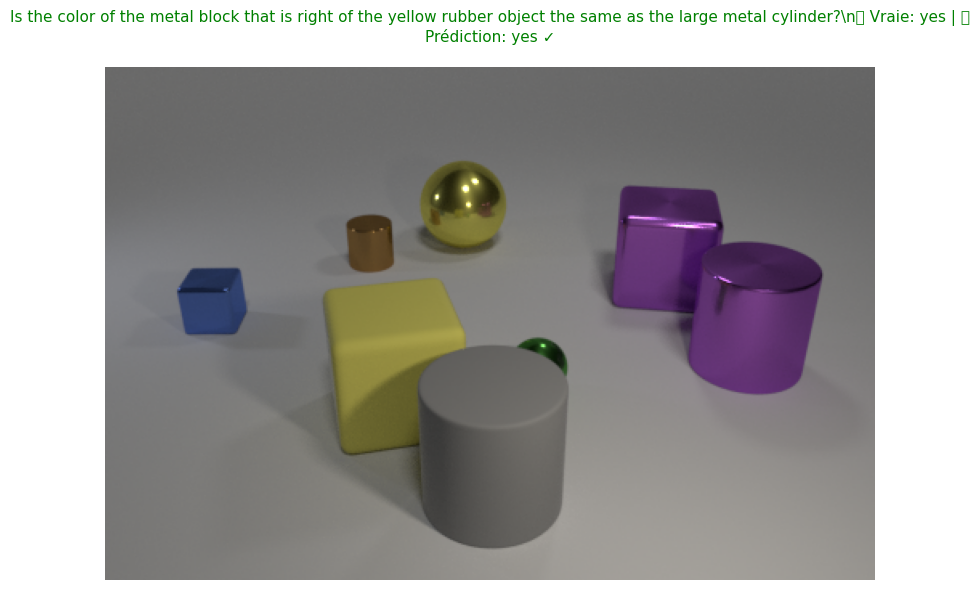

DEBUG PngImagePlugin.py: 203: STREAM b'IHDR' 16 13
DEBUG PngImagePlugin.py: 203: STREAM b'pHYs' 41 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 62 111
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 185 24
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 221 16
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 249 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 270 13
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 295 11
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 318 19
DEBUG PngImagePlugin.py: 203: STREAM b'IDAT' 349 8192


\n📌 Exemple 2/3
--------------------------------------------------------------------------------
❓ Question: The other object that is the same color as the large shiny thing is what shape?
✅ Vraie réponse: cylinder
🤖 Prédiction du modèle: cylinder
✓ Le modèle a donné la bonne réponse!


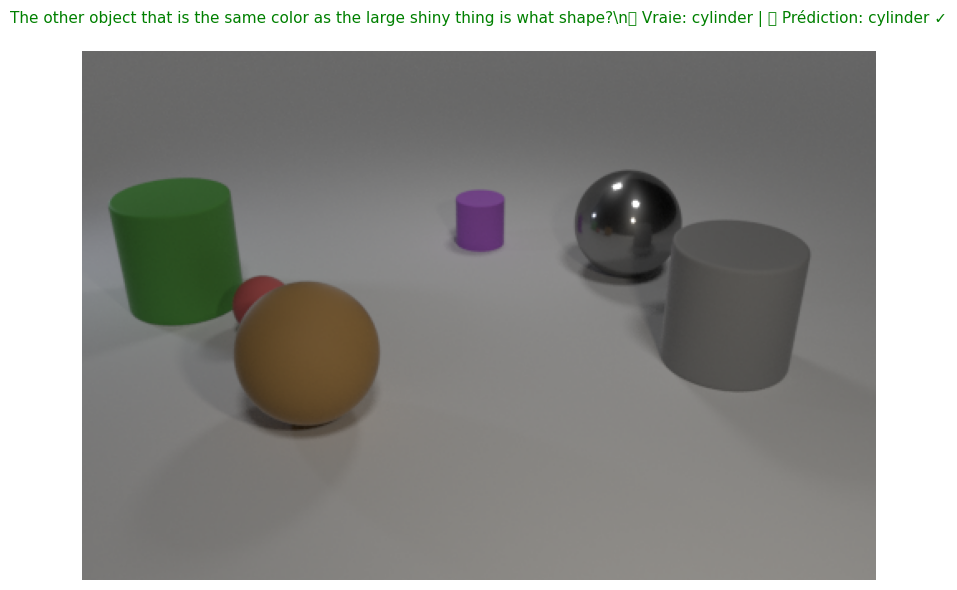

DEBUG PngImagePlugin.py: 203: STREAM b'IHDR' 16 13
DEBUG PngImagePlugin.py: 203: STREAM b'pHYs' 41 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 62 111
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 185 24
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 221 16
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 249 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 270 13
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 295 11
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 318 19
DEBUG PngImagePlugin.py: 203: STREAM b'IDAT' 349 8192


\n📌 Exemple 3/3
--------------------------------------------------------------------------------
❓ Question: Is the material of the yellow block the same as the yellow cylinder?
✅ Vraie réponse: no
🤖 Prédiction du modèle: no
✓ Le modèle a donné la bonne réponse!


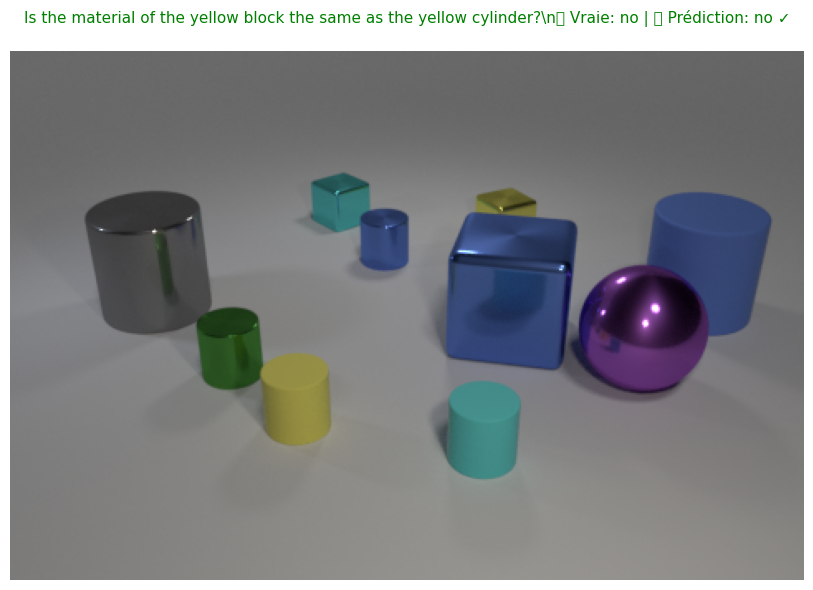

\n================================================================================
✅ Visualisation terminée!


In [43]:
import json
import torch
from PIL import Image
import matplotlib.pyplot as plt
import random

print("🎨 Visualisation d'une prédiction du modèle\\n")
print("=" * 80)

# Charger les questions de validation - utiliser le chemin dynamique
val_questions_path = os.path.join(OUTPUT_DIR, 'temp', f'val_questions_{VAL_SIZE}.json')
with open(val_questions_path, 'r') as f:
    val_questions = json.load(f)['questions']

# Choisir quelques échantillons aléatoires
num_examples = 3
indices = random.sample(range(min(len(val_questions), len(val_dataset))), num_examples)

# Charger le fichier de prédictions si disponible
predictions_file = "curr_valid_predictions.txt"  # À la racine du projet
predictions_dict = {}

try:
    with open(predictions_file, 'r') as f:
        for line in f:
            parts = line.strip().split(' ')
            if len(parts) >= 4:
                pred_ans = parts[0]
                true_ans = parts[1]
                img_num = parts[2]
                question = ' '.join(parts[3:])
                # Normaliser la question: enlever <START> et <END>, mettre en minuscules
                question = question.replace('<START>', '').replace('<END>', '').strip().lower()
                predictions_dict[question] = (pred_ans, true_ans, img_num)
except FileNotFoundError:
    print(f"⚠️ Fichier de prédictions non trouvé: {predictions_file}")
    print("Les prédictions seront calculées à la volée...")

# Afficher les exemples
for i, idx in enumerate(indices):
    print(f"\\n📌 Exemple {i+1}/{num_examples}")
    print("-" * 80)
    
    # Récupérer la question du JSON
    question_data = val_questions[idx]
    question_text = question_data['question']
    true_answer = question_data['answer']
    image_filename = question_data['image_filename']
    image_idx = question_data['image_index']
    
    print(f"❓ Question: {question_text}")
    print(f"✅ Vraie réponse: {true_answer}")
    
    # Chercher dans les prédictions (normaliser la question pour le matching)
    question_normalized = question_text.lower().replace('?', '').strip()
    if question_normalized in predictions_dict:
        pred_answer, _, _ = predictions_dict[question_normalized]
        print(f"🤖 Prédiction du modèle: {pred_answer}")
        
        correct = (pred_answer == true_answer)
        if correct:
            print("✓ Le modèle a donné la bonne réponse!")
        else:
            print(f"✗ Le modèle s'est trompé.")
    else:
        print(f"🤖 Prédiction: (non disponible - question pas dans les prédictions)")
    
    # Afficher l'image - utiliser des chemins relatifs
    # Déterminer le bon dossier (train ou val) selon le nom de fichier
    if 'train' in image_filename.lower():
        image_path = os.path.join('data', 'CLEVR_v1.0', 'images', 'train', image_filename)
    elif 'val' in image_filename.lower():
        image_path = os.path.join('data', 'CLEVR_v1.0', 'images', 'val', image_filename)
    else:
        image_path = os.path.join('data', 'CLEVR_v1.0', 'images', 'train', image_filename)  # Fallback
    
    try:
        img = Image.open(image_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        
        # Titre avec question et réponse
        if question_normalized in predictions_dict:
            pred_answer, _, _ = predictions_dict[question_normalized]
            correct = (pred_answer == true_answer)
            title_color = 'green' if correct else 'red'
            result_emoji = '✓' if correct else '✗'
            title = f"{question_text}\\n✅ Vraie: {true_answer} | 🤖 Prédiction: {pred_answer} {result_emoji}"
        else:
            title = f"{question_text}\\n✅ Vraie réponse: {true_answer}"
            title_color = 'black'
        
        plt.title(title, fontsize=11, pad=20, color=title_color, wrap=True)
        plt.tight_layout()
        plt.show()
        
    except FileNotFoundError:
        print(f"⚠️ Image non trouvée: {image_path}")

print("\\n" + "=" * 80)
print(f"✅ Visualisation terminée!")

🔍 Préparation de la visualisation...
✅ Modèle GAT détecté
📦 Chargement d'un exemple du dataset de validation...
✅ Batch chargé:
   - Questions shape: torch.Size([16, 37])
   - Batch size: 16
   - Questions graph: 160 noeuds
   - Scènes graph: 575 noeuds

📝 Récupération des métadonnées pour les labels...
   📝 Question complète (15 mots): Are there any other things that are the same shape as the big metallic object
   📊 Graphe de question: 11 noeuds
   🖼️ Image: CLEVR_val_000000.png (index #0)
   🎯 Scène: 5 objets détectés
      1. large rubber brown cylinder (brocyl)
      2. large rubber gray cube (gracub)
      3. small rubber green cylinder (grecyl)
      4. large metal purple sphere (pursph)
      5. small metal gray cube (gracub)

✅ Labels créés:
   📝 Question: 11 noeuds dans le graphe syntaxique
      Question complète: Are there any other things that are the same shape as the big metallic object
      ⚠️ Le parser syntaxique crée 11 noeuds pour 15 mots
         (certains mots son

DEBUG colorbar.py: 867: locator: <matplotlib.ticker.AutoLocator object at 0x000001C6165CAFF0>


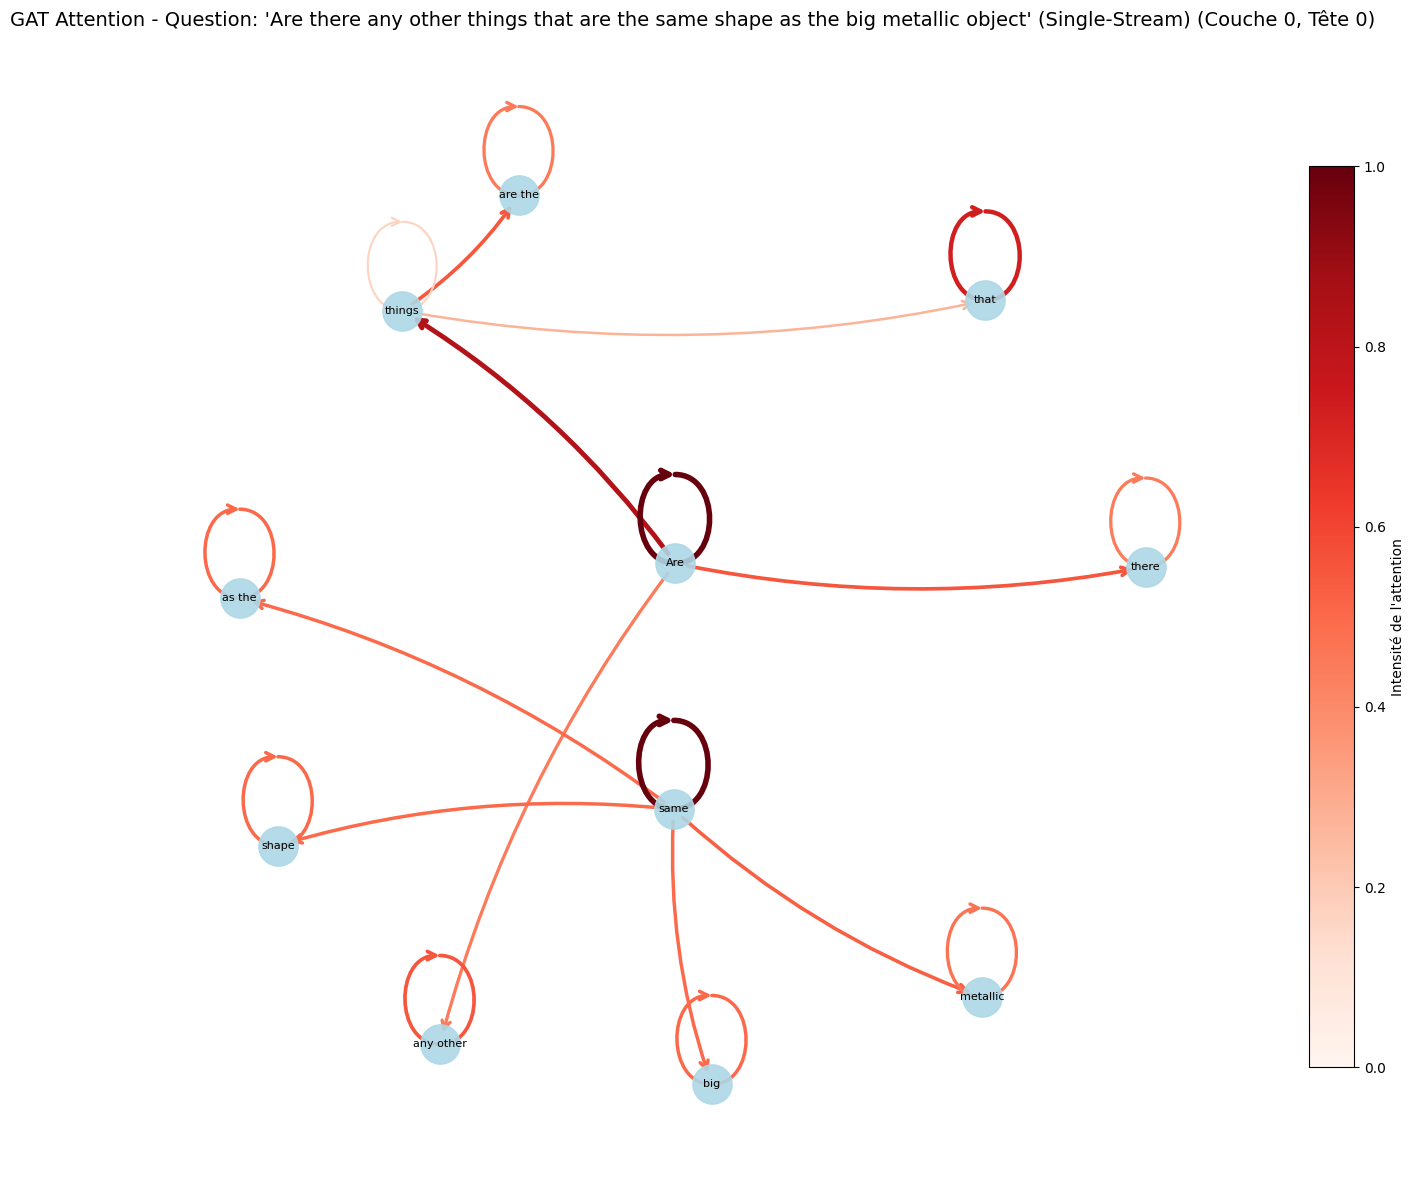

DEBUG PngImagePlugin.py: 203: STREAM b'IHDR' 16 13
DEBUG PngImagePlugin.py: 203: STREAM b'pHYs' 41 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 62 111
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 185 24
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 221 16
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 249 9
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 270 13
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 295 11
DEBUG PngImagePlugin.py: 203: STREAM b'tEXt' 318 19
DEBUG PngImagePlugin.py: 203: STREAM b'IDAT' 349 8192


✅ Graphe visualisé: 11 noeuds, 20 arêtes (seuil > 0.05)
   Attention min/max: 0.1691 / 1.0000

   → 🖼️ IMAGE DE LA SCÈNE



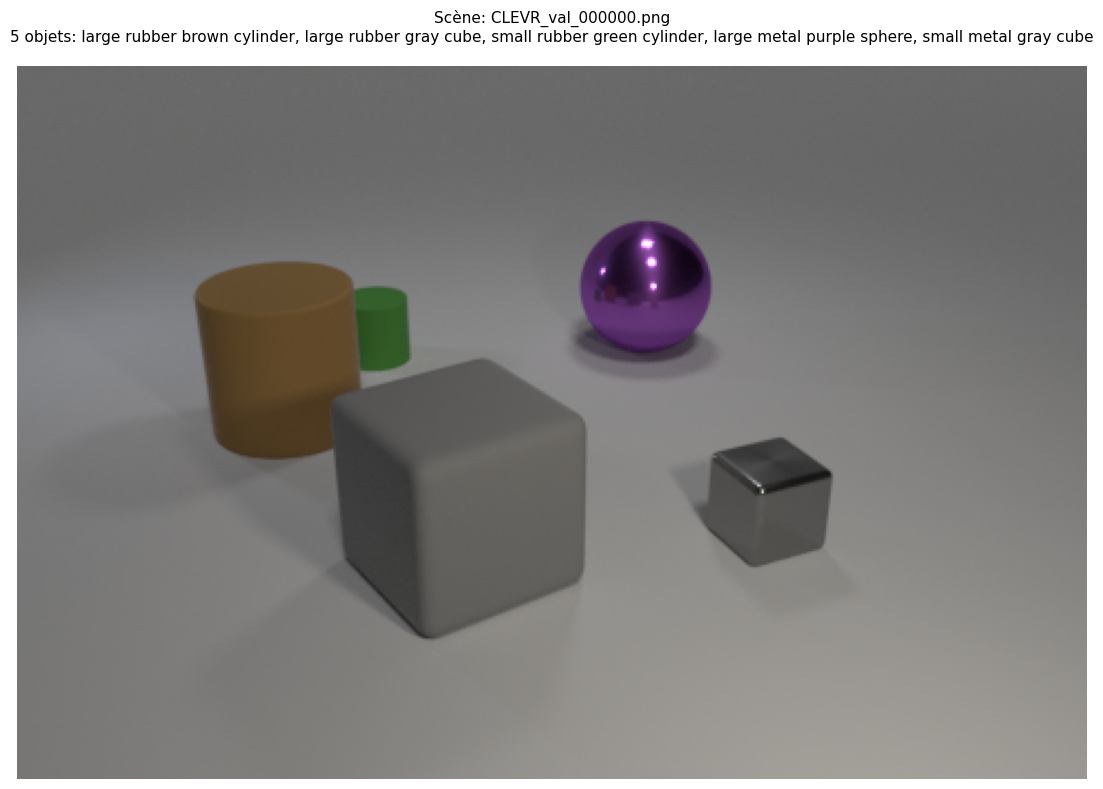


   → Visualisation du graphe SCÈNE (même GNN partagé)



DEBUG colorbar.py: 867: locator: <matplotlib.ticker.AutoLocator object at 0x000001C6364DB9B0>


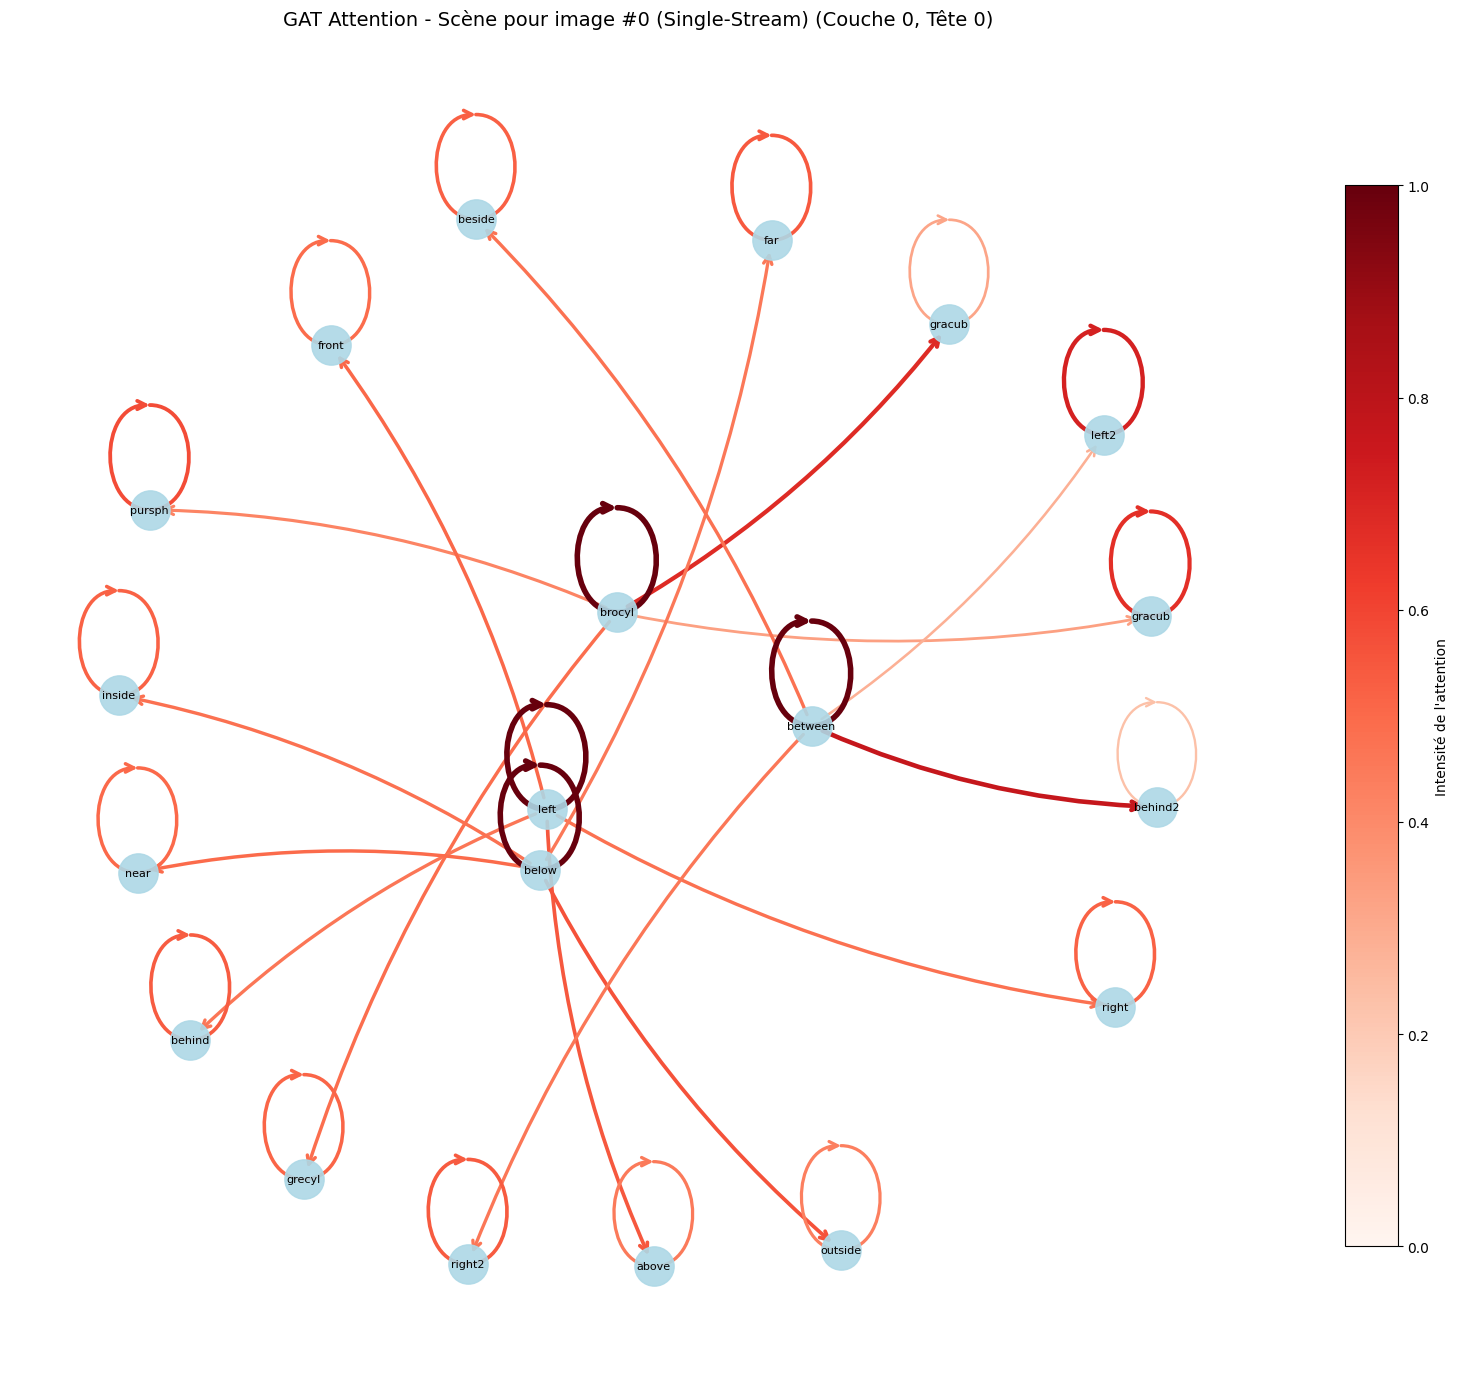

✅ Graphe visualisé: 20 noeuds, 36 arêtes (seuil > 0.05)
   Attention min/max: 0.2332 / 1.0000

🎉 Visualisation terminée avec les vrais noms des noeuds!

💡 Légendes:
   - Question: mots regroupés selon l'analyse syntaxique du parser
     (le parser crée des nœuds pour les concepts clés, pas mot-à-mot)
   - Scène: objets au format 'couleurshape' (ex: redcub = red cube)
   - Relations spatiales: left, right, behind, front, near, etc.
     (encodent les positions relatives entre objets)

💡 Pour changer l'architecture:
   - Mode single-stream: opt.two_stream_gnn = 0 (GNN partagé)
   - Mode two-stream: opt.two_stream_gnn = 1 (2 GNN séparés)


In [51]:
# 🔍 Visualisation de l'attention GAT sur un exemple réel avec noms des noeuds
import torch
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import json
from PIL import Image

def visualize_gat_attention(gat_model, x, edge_index, layer_idx=0, head_idx=0, 
                            node_labels=None, title="GAT Attention", 
                            figsize=(12, 10), threshold=0.05):
    """
    Visualise le graphe d'attention d'une couche spécifique du GAT.
    
    Args:
        gat_model: Instance de GAT (models.gnn.GAT)
        x: Features des noeuds (Tensor) [num_nodes, feature_dim]
        edge_index: Indices des arêtes (Tensor) [2, num_edges]
        layer_idx: Indice de la couche à visualiser (0, 1, ...)
        head_idx: Indice de la tête d'attention (0 à heads-1)
        node_labels: Liste des noms des noeuds
        threshold: Seuil min d'attention pour afficher une arête (0.0 à 1.0)
    """
    gat_model.eval()
    with torch.no_grad():
        # Récupérer les poids d'attention
        out, attn_list = gat_model(x, edge_index, return_attention=True)
        
        # attn_list[layer_idx] = (edge_index, alpha_scores)
        # alpha_scores: [num_edges, num_heads]
        edge_idx_layer, alpha = attn_list[layer_idx]
        attn_weights = alpha[:, head_idx].cpu().numpy()
        
    # Construction du graphe NetworkX
    sources = edge_idx_layer[0].cpu().numpy()
    targets = edge_idx_layer[1].cpu().numpy()
    
    G = nx.DiGraph()
    num_nodes = x.shape[0]
    
    # Ajouter les noeuds avec labels
    for i in range(num_nodes):
        label = node_labels[i] if node_labels and i < len(node_labels) else f"N{i}"
        G.add_node(i, label=label)
    
    # Filtrer les arêtes par seuil et préparer les visualisations
    edges_to_draw = []
    colors = []
    widths = []
    
    for s, t, w in zip(sources, targets, attn_weights):
        if w > threshold:
            G.add_edge(s, t, weight=w)
            edges_to_draw.append((s, t))
            colors.append(w)
            widths.append(1 + w * 3)  # Largeur proportionnelle
    
    # Dessin
    fig, ax = plt.subplots(figsize=figsize)
    
    # Layout circulaire pour les petits graphes, spring pour les grands
    # Utiliser spring avec plus d'itérations pour éviter la séparation
    if num_nodes <= 15:
        pos = nx.spring_layout(G, k=2.0, iterations=100, seed=42)
    else:
        pos = nx.spring_layout(G, k=1.8, iterations=100, seed=42)
    
    # Noeuds
    nx.draw_networkx_nodes(G, pos, node_size=800, node_color='lightblue', 
                          alpha=0.9, ax=ax)
    nx.draw_networkx_labels(G, pos, labels=nx.get_node_attributes(G, 'label'), 
                           font_size=8, ax=ax)
    
    # Arêtes avec colormap
    if edges_to_draw:
        edge_collection = nx.draw_networkx_edges(
            G, pos, edgelist=edges_to_draw, width=widths, 
            edge_color=colors, edge_cmap=plt.cm.Reds, 
            edge_vmin=0, edge_vmax=1,
            arrowstyle='->', arrowsize=15,
            connectionstyle='arc3,rad=0.1', ax=ax
        )
        
        # Colorbar
        sm = plt.cm.ScalarMappable(cmap=plt.cm.Reds, 
                                   norm=plt.Normalize(vmin=0, vmax=1))
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, label="Intensité de l'attention", shrink=0.8)
    
    ax.set_title(f"{title} (Couche {layer_idx}, Tête {head_idx})", fontsize=14, pad=20)
    ax.axis('off')
    plt.tight_layout()
    plt.show()
    
    print(f"✅ Graphe visualisé: {num_nodes} noeuds, {len(edges_to_draw)} arêtes (seuil > {threshold})")
    print(f"   Attention min/max: {attn_weights.min():.4f} / {attn_weights.max():.4f}")

# ════════════════════════════════════════════════════════════════════════════
# 📊 EXEMPLE D'UTILISATION AVEC DONNÉES RÉELLES ET NOMS DES NOEUDS
# ════════════════════════════════════════════════════════════════════════════

print("🔍 Préparation de la visualisation...")
print("=" * 80)

# 1️⃣ Vérifier qu'on utilise un GAT
if opt.gnn != 'gat':
    print(f"⚠️ Le modèle actuel utilise {opt.gnn.upper()}, pas GAT")
    print("   Pour visualiser l'attention, changez opt.gnn = 'gat' et réentraînez")
    print()
    print("💡 Alternative: Visualiser la structure du graphe sans attention")
else:
    print(f"✅ Modèle GAT détecté")

# 2️⃣ Récupérer un exemple du dataset de validation
print(f"📦 Chargement d'un exemple du dataset de validation...")

# Prendre le premier batch
batch = next(iter(val_loader))
# Le batch contient: questions, programs, answers, image_idxs, g_data_batch
questions, programs, answers, image_idxs, g_data_batch = batch

print(f"✅ Batch chargé:")
print(f"   - Questions shape: {questions.shape}")
print(f"   - Batch size: {len(image_idxs)}")

# g_data_batch est un tuple (BATCH_S, BATCH_T) pour questions et scènes
BATCH_S, BATCH_T = g_data_batch

print(f"   - Questions graph: {BATCH_S.x.shape[0]} noeuds")
print(f"   - Scènes graph: {BATCH_T.x.shape[0]} noeuds")
print()

# 3️⃣ Extraire le premier graphe (question) du batch
idx_to_extract = 0  # Premier graphe du batch

# Masque pour les noeuds du premier graphe
mask_s = BATCH_S.batch == idx_to_extract
mask_t = BATCH_T.batch == idx_to_extract

# Extraire les features
x_question = BATCH_S.x[mask_s]
x_scene = BATCH_T.x[mask_t]

# Extraire edge_index
edge_mask_s = mask_s[BATCH_S.edge_index[0]] & mask_s[BATCH_S.edge_index[1]]
edge_index_s = BATCH_S.edge_index[:, edge_mask_s]

edge_mask_t = mask_t[BATCH_T.edge_index[0]] & mask_t[BATCH_T.edge_index[1]]
edge_index_t = BATCH_T.edge_index[:, edge_mask_t]

# Renuméroter les noeuds
node_mapping_s = {old_idx.item(): new_idx for new_idx, old_idx in enumerate(torch.where(mask_s)[0])}
node_mapping_t = {old_idx.item(): new_idx for new_idx, old_idx in enumerate(torch.where(mask_t)[0])}

edge_index_s_remapped = torch.tensor([
    [node_mapping_s[src.item()] for src in edge_index_s[0]],
    [node_mapping_s[tgt.item()] for tgt in edge_index_s[1]]
], dtype=torch.long)

edge_index_t_remapped = torch.tensor([
    [node_mapping_t[src.item()] for src in edge_index_t[0]],
    [node_mapping_t[tgt.item()] for tgt in edge_index_t[1]]
], dtype=torch.long)

# 🔥 RÉCUPÉRER LES MÉTADONNÉES POUR LES LABELS
print("📝 Récupération des métadonnées pour les labels...")

# Pour la question: convertir les indices de tokens en mots
vocab = val_dataset.vocab
question_tokens = questions[idx_to_extract].cpu().numpy()

# 🔥 CORRECTION: Récupérer TOUS les mots jusqu'au token <END>
question_words_all = []
for token_idx in question_tokens:
    if token_idx in vocab['question_idx_to_token']:
        word = vocab['question_idx_to_token'][token_idx]
        if word == '<END>':
            break  # Arrêter au token de fin
        if word not in ['<NULL>', '<START>']:
            question_words_all.append(word)

print(f"   📝 Question complète ({len(question_words_all)} mots): {' '.join(question_words_all)}")
print(f"   📊 Graphe de question: {x_question.shape[0]} noeuds")

# Pour la scène: récupérer les objets depuis les métadonnées
image_idx = image_idxs[idx_to_extract].item()

# Charger les questions et scènes depuis les JSON pour avoir toutes les infos
val_questions_path = os.path.join(OUTPUT_DIR, 'temp', f'val_questions_{VAL_SIZE}.json')
with open(val_questions_path, 'r') as f:
    val_questions_json = json.load(f)['questions']

# Trouver la question correspondante
question_data = val_questions_json[idx_to_extract]
image_filename = question_data['image_filename']

print(f"   🖼️ Image: {image_filename} (index #{image_idx})")

# Charger les scènes depuis le JSON
with open(opt.clevr_val_scene_path, 'r') as f:
    scenes_data = json.load(f)
    
# Trouver la scène correspondante
scene = None
for s in scenes_data['scenes']:
    if s['image_index'] == image_idx:
        scene = s
        break

if scene:
    # Extraire les objets de la scène
    scene_objects = []
    scene_objects_full = []  # Version complète pour l'affichage
    for obj in scene['objects']:
        size = obj.get('size', '')
        color = obj.get('color', '')
        shape = obj.get('shape', '')
        material = obj.get('material', '')
        
        # Label compact pour le graphe
        label = f"{color[:3]}{shape[:3]}"  # Ex: "redcub"
        scene_objects.append(label)
        
        # Label complet pour l'affichage
        full_label = f"{size} {material} {color} {shape}"
        scene_objects_full.append(full_label)
    
    print(f"   🎯 Scène: {len(scene_objects)} objets détectés")
    for i, obj_full in enumerate(scene_objects_full):
        print(f"      {i+1}. {obj_full} ({scene_objects[i]})")
else:
    scene_objects = [f"O{i}" for i in range(x_scene.shape[0])]
    scene_objects_full = scene_objects
    print(f"   ⚠️ Scène non trouvée, utilisation de labels génériques")

# Adapter les labels à la taille des graphes
# 🔥 Le parser syntaxique crée MOINS de noeuds que de mots car il regroupe les concepts
# Par exemple: "the big metallic object" peut devenir un seul nœud "object"
# Pour une meilleure visualisation, on va essayer de distribuer les mots sur les nœuds
question_labels = []
if len(question_words_all) <= x_question.shape[0]:
    # Plus de noeuds que de mots : certains sont des relations
    for i in range(x_question.shape[0]):
        if i < len(question_words_all):
            question_labels.append(question_words_all[i])
        else:
            question_labels.append(f"syntrel_{i}")  # Relations syntaxiques
else:
    # Plus de mots que de noeuds : regrouper les mots
    # Essayer de distribuer équitablement
    words_per_node = len(question_words_all) / x_question.shape[0]
    for i in range(x_question.shape[0]):
        start_idx = int(i * words_per_node)
        end_idx = int((i + 1) * words_per_node)
        node_words = question_words_all[start_idx:end_idx]
        if node_words:
            question_labels.append(' '.join(node_words))
        else:
            question_labels.append(f"Q{i}")

# Pour la scène: labels plus explicites pour les relations spatiales
scene_labels = []
# Noms des relations spatiales possibles dans CLEVR
spatial_relations = ['left', 'right', 'behind', 'front', 'above', 'below', 
                    'near', 'far', 'inside', 'outside', 'between', 'beside']
for i in range(x_scene.shape[0]):
    if i < len(scene_objects):
        scene_labels.append(scene_objects[i])
    else:
        # Relations spatiales avec noms rotatifs
        rel_idx = (i - len(scene_objects)) % len(spatial_relations)
        rel_num = (i - len(scene_objects)) // len(spatial_relations) + 1
        if rel_num == 1:
            scene_labels.append(f"{spatial_relations[rel_idx]}")
        else:
            scene_labels.append(f"{spatial_relations[rel_idx]}{rel_num}")

print(f"\n✅ Labels créés:")
print(f"   📝 Question: {x_question.shape[0]} noeuds dans le graphe syntaxique")
print(f"      Question complète: {' '.join(question_words_all)}")
print(f"      ⚠️ Le parser syntaxique crée {x_question.shape[0]} noeuds pour {len(question_words_all)} mots")
print(f"         (certains mots sont regroupés en concepts syntaxiques)")
print(f"      Labels graphe: {question_labels}")
print(f"   🖼️ Scène: {x_scene.shape[0]} noeuds")
print(f"      Objets ({len(scene_objects)}): {scene_objects}")
print(f"      Labels graphe: {scene_labels[:min(15, len(scene_labels))]}")
if len(scene_labels) > 15:
    print(f"      ... et {len(scene_labels)-15} relations spatiales supplémentaires")
print()

# 4️⃣ Visualisation avec les vrais noms
if opt.two_stream_gnn:
    print("🔀 Mode TWO-STREAM détecté")
    gat_question = model.seq2seq.gnn.psi_1
    gat_scene = model.seq2seq.gnn.psi_2
    
    print("   → Visualisation du graphe QUESTION (psi_1)")
    print()
    
    if opt.gnn == 'gat':
        visualize_gat_attention(
            gat_model=gat_question,
            x=x_question,
            edge_index=edge_index_s_remapped,
            layer_idx=0,
            head_idx=0,
            node_labels=question_labels,
            title=f"GAT Attention - Question: '{' '.join(question_words_all[:8])}...' (psi_1)",
            threshold=0.05
        )
    
    print()
    print("   → Visualisation du graphe SCÈNE (psi_2)")
    print()
    
    if opt.gnn == 'gat':
        visualize_gat_attention(
            gat_model=gat_scene,
            x=x_scene,
            edge_index=edge_index_t_remapped,
            layer_idx=0,
            head_idx=0,
            node_labels=scene_labels,
            title="GAT Attention - Scène (psi_2)",
            threshold=0.05
        )
else:
    print("📊 Mode SINGLE-STREAM détecté")
    gat_shared = model.seq2seq.gnn.psi_1
    
    print("   → Visualisation du graphe QUESTION (GNN partagé)")
    print()
    
    if opt.gnn == 'gat':
        visualize_gat_attention(
            gat_model=gat_shared,
            x=x_question,
            edge_index=edge_index_s_remapped,
            layer_idx=0,
            head_idx=0,
            node_labels=question_labels,
            title=f"GAT Attention - Question: '{' '.join(question_words_all)}' (Single-Stream)",
            threshold=0.05,
            figsize=(14, 12)
        )
    
    print()
    print("   → 🖼️ IMAGE DE LA SCÈNE")
    print()
    
    # 🔥 AJOUT: Afficher l'image de la scène
    if 'val' in image_filename.lower():
        image_path = os.path.join('data', 'CLEVR_v1.0', 'images', 'val', image_filename)
    else:
        image_path = os.path.join('data', 'CLEVR_v1.0', 'images', 'train', image_filename)
    
    try:
        img = Image.open(image_path)
        plt.figure(figsize=(12, 8))
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Scène: {image_filename}\n{len(scene_objects)} objets: {', '.join(scene_objects_full)}", 
                 fontsize=11, pad=20, wrap=True)
        plt.tight_layout()
        plt.show()
    except FileNotFoundError:
        print(f"⚠️ Image non trouvée: {image_path}")
    
    print()
    print("   → Visualisation du graphe SCÈNE (même GNN partagé)")
    print()
    
    if opt.gnn == 'gat':
        visualize_gat_attention(
            gat_model=gat_shared,
            x=x_scene,
            edge_index=edge_index_t_remapped,
            layer_idx=0,
            head_idx=0,
            node_labels=scene_labels,
            title=f"GAT Attention - Scène pour image #{image_idx} (Single-Stream)",
            threshold=0.05,
            figsize=(16, 14)
        )

print()
print("=" * 80)
print("🎉 Visualisation terminée avec les vrais noms des noeuds!")
print()
print("💡 Légendes:")
print("   - Question: mots regroupés selon l'analyse syntaxique du parser")
print("     (le parser crée des nœuds pour les concepts clés, pas mot-à-mot)")
print("   - Scène: objets au format 'couleurshape' (ex: redcub = red cube)")
print("   - Relations spatiales: left, right, behind, front, near, etc.")
print("     (encodent les positions relatives entre objets)")
print()
print("💡 Pour changer l'architecture:")
print("   - Mode single-stream: opt.two_stream_gnn = 0 (GNN partagé)")
print("   - Mode two-stream: opt.two_stream_gnn = 1 (2 GNN séparés)")